# 🔍 Exploration — qui part, et pourquoi ?

Jeu de données *Telco Customer Churn* (IBM) : 7 043 clients d'un opérateur télécom, leurs services, leur contrat,
leur facture, et s'ils sont partis le mois dernier (`churn`).

In [1]:
import sys
sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import pandas as pd
from churn import data as D

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = D.load_dataset()
s = D.summary(df)
print(f"{s['clients']} clients · {s['taux_churn']:.1%} de départs · "
      f"{s['revenu_mensuel_perdu'] / s['revenu_mensuel_total']:.0%} du revenu mensuel perdu")
df.head()

7043 clients · 26.5% de départs · 31% du revenu mensuel perdu


,id_client,genre,senior,en_couple,personnes_a_charge,anciennete_mois,telephone,lignes_multiples,internet,securite_en_ligne,...,streaming_tv,streaming_films,contrat,facture_dematerialisee,moyen_paiement,facture_mensuelle,total_facture,churn,nb_services,tranche_anciennete
0,7590-VHVEG,Femme,Non,Oui,Non,1,Non,Pas de téléphone,DSL,Non,...,Non,Non,Mensuel,Oui,Chèque électronique,29.85,29.85,0,1,0-6 mois
1,5575-GNVDE,Homme,Non,Non,Non,34,Oui,Non,DSL,Oui,...,Non,Non,1 an,Non,Chèque postal,56.95,1889.50,0,2,25-48 mois
2,3668-QPYBK,Homme,Non,Non,Non,2,Oui,Non,DSL,Oui,...,Non,Non,Mensuel,Oui,Chèque postal,53.85,108.15,1,2,0-6 mois
3,7795-CFOCW,Homme,Non,Non,Non,45,Non,Pas de téléphone,DSL,Oui,...,Non,Non,1 an,Non,Virement automatique,42.30,1840.75,0,3,25-48 mois
4,9237-HQITU,Femme,Non,Non,Non,2,Oui,Non,Fibre optique,Non,...,Non,Non,Mensuel,Oui,Chèque électronique,70.70,151.65,1,0,0-6 mois


## 1. Les quatre signaux les plus forts

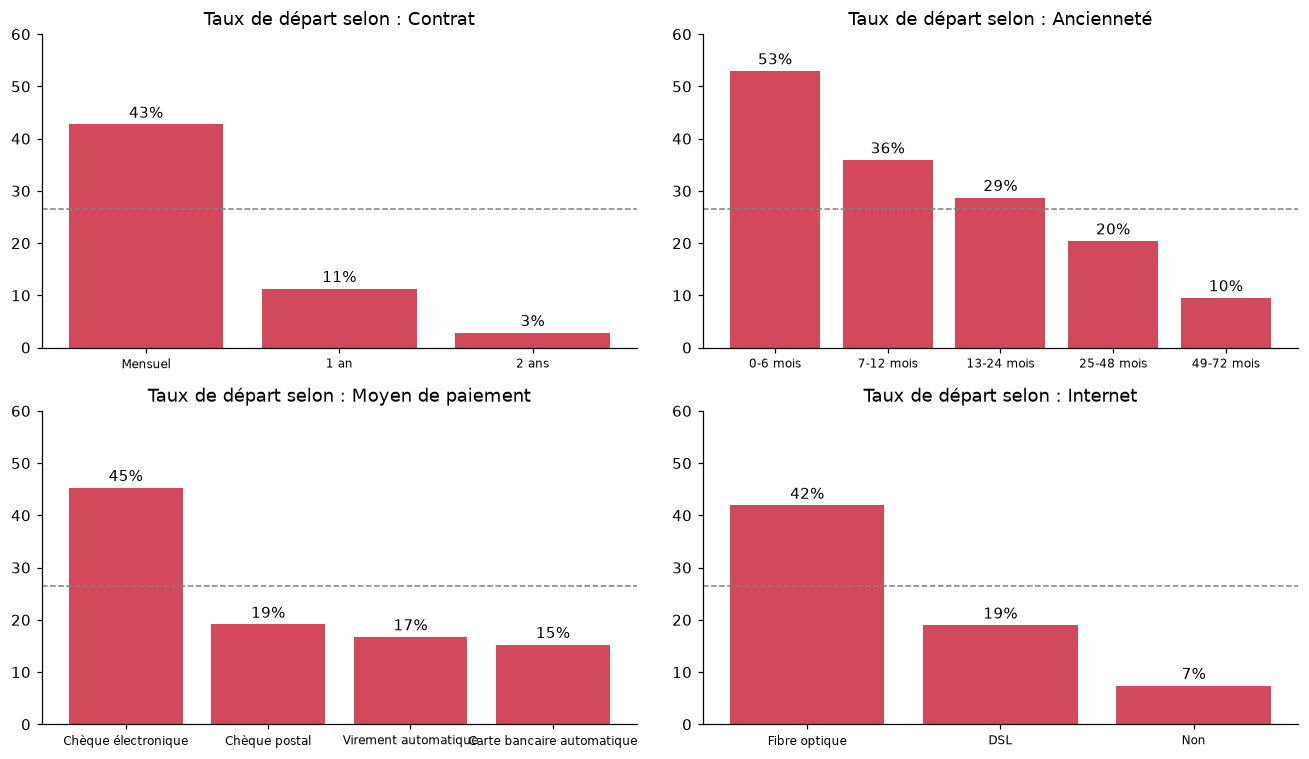

In [2]:
def rate(col, order=None):
    g = df.groupby(col)["churn"].agg(["mean", "size"])
    return g.reindex(order) if order else g.sort_values("mean", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
specs = [("contrat", ["Mensuel", "1 an", "2 ans"], "Contrat"),
         ("tranche_anciennete", D.TENURE_LABELS, "Ancienneté"),
         ("moyen_paiement", None, "Moyen de paiement"),
         ("internet", ["Fibre optique", "DSL", "Non"], "Internet")]
for ax, (col, order, title) in zip(axes.flat, specs):
    g = rate(col, order)
    bars = ax.bar(g.index, g["mean"] * 100, color="#d1495b")
    ax.bar_label(bars, labels=[f"{m:.0%}" for m in g["mean"]], padding=2)
    ax.axhline(26.5, color="grey", ls="--", lw=1)
    ax.set_title(f"Taux de départ selon : {title}"); ax.set_ylim(0, 60); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**➜ Le profil du client qui part :** contrat **mensuel** (43 % de départs contre 3 % pour 2 ans), **nouveau client**
(53 % de départs les 6 premiers mois), **fibre optique** (42 %) et paiement par **chèque électronique** (45 %).

La ligne pointillée marque la moyenne (26,5 %).

## 2. Les services d'accompagnement retiennent les clients

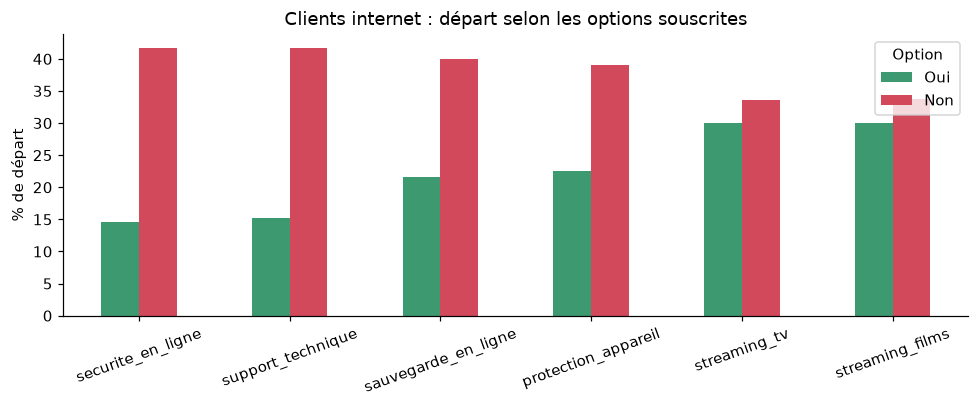

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
svc = ["securite_en_ligne", "support_technique", "sauvegarde_en_ligne", "protection_appareil", "streaming_tv", "streaming_films"]
internet = df[df["internet"] != "Non"]
vals = pd.DataFrame({s: internet.groupby(s)["churn"].mean() for s in svc}).T[["Oui", "Non"]] * 100
vals.plot(kind="bar", ax=ax, color=["#3d9970", "#d1495b"], rot=20)
ax.set_ylabel("% de départ"); ax.set_title("Clients internet : départ selon les options souscrites"); ax.legend(title="Option")
plt.tight_layout(); plt.show()

**➜ Sécurité en ligne et support technique** divisent le risque de départ par près de trois (42 % → 15 %).
Le streaming, lui, ne retient pas : ce n'est pas une question de « nombre d'options », mais de **services qui accompagnent le client**.

## 3. Deux pièges pour la modélisation

In [4]:
from sklearn.linear_model import LinearRegression
svc_cols = ["telephone", "lignes_multiples", "internet"] + D.SERVICES
X = pd.get_dummies(df[svc_cols], drop_first=True)
r2 = LinearRegression().fit(X, df["facture_mensuelle"]).score(X, df["facture_mensuelle"])
print(f"La facture mensuelle s'explique à {r2:.1%} par les services souscrits")
print(f"Corrélation total facturé / ancienneté : {df['total_facture'].corr(df['anciennete_mois']):.2f}")

La facture mensuelle s'explique à 99.9% par les services souscrits
Corrélation total facturé / ancienneté : 0.83


- La **facture mensuelle** est le prix des services : elle n'apporte aucune information nouvelle.
- Le **total facturé** ≈ ancienneté × facture mensuelle.

Garder ces deux variables à côté de l'ancienneté et des services rendait les coefficients du modèle instables
et les **motifs de départ absurdes** (« total facturé élevé » présenté comme une raison de partir).
Elles sont donc **retirées du modèle**, et gardées pour calculer la valeur de chaque client.